In [ ]:
import sys
import platform
import torch

print("Python version :", sys.version)
print("Platform       :", platform.platform())
print("CUDA Available :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Tip: Go to Runtime -> Change runtime type -> T4 GPU for faster training)")


Python version : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform       : Linux-6.6.122+-x86_64-with-glibc2.39
CUDA Available : True
GPU Device Name: Tesla T4


In [ ]:
!pip install -U ultralytics opencv-python matplotlib pandas numpy seaborn scikit-learn pillow pyyaml tqdm


In [16]:
from pathlib import Path
import os
import sys
import json
import yaml
import shutil
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image
from tqdm.auto import tqdm

import torch
import ultralytics
from ultralytics import YOLO

warnings.filterwarnings("ignore")

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version    :", torch.__version__)
print("YOLO imported successfully.")


Ultralytics version: 8.4.173
PyTorch version    : 2.11.0+cu130
YOLO imported successfully.


In [15]:
!unzip -q /content/chenab_dataset/chenab_dataset.zip -d /content/chenab_dataset/

In [21]:
PROJECT_ROOT = Path("/content/fabric_defect_detection")

# Direct path to the folder dragged & dropped into Colab
DATASET_DIR = Path("/content/chenab_dataset")
DATA_YAML = DATASET_DIR / "data.yaml"

RUNS_DIR = PROJECT_ROOT / "runs"
RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
MODELS_DIR = PROJECT_ROOT / "models"

# Create output directories
for directory in [RUNS_DIR, RESULTS_DIR, OUTPUTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Dataset folder exists:", DATASET_DIR.exists())
print("data.yaml exists     :", DATA_YAML.exists())

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Folder not found at: {DATASET_DIR}\n"
        "Please drag & drop 'chenab_yolov12_cpu_paper_reproduction' directly into Colab's Files panel on the left."
    )

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"data.yaml not found inside: {DATASET_DIR}\n"
        "Please ensure the folder contains data.yaml, train, valid, and test subfolders."
    )

print("All directory paths configured successfully!")


Dataset folder exists: True
data.yaml exists     : True
All directory paths configured successfully!


In [22]:
print("\nDataset structure:\n")
for item in sorted(DATASET_DIR.iterdir()):
    if item.is_dir():
        print(f"[DIR ] {item.name}")
        for subitem in sorted(item.iterdir())[:3]:
            print(f"       └── {subitem.name}")
    else:
        print(f"[FILE] {item.name}")



Dataset structure:

[FILE] README.roboflow.txt
[FILE] chenab_dataset.zip
[FILE] data.yaml
[FILE] paper_reproduction.yaml
[DIR ] test
       └── images
       └── labels
       └── labels.cache
[DIR ] train
       └── images
       └── labels
       └── labels.cache
[DIR ] valid
       └── images
       └── labels
       └── labels.cache


In [23]:
with open(DATA_YAML, "r", encoding="utf-8") as f:
    original_config = yaml.safe_load(f)

print("Original data.yaml:")
print(json.dumps(original_config, indent=4, default=str))

names = original_config.get("names")
if names is None:
    raise ValueError("Class names were not found in data.yaml")

if isinstance(names, dict):
    CLASS_NAMES = [names[k] for k in sorted(names.keys())]
else:
    CLASS_NAMES = list(names)

NUM_CLASSES = len(CLASS_NAMES)
print("\nNumber of classes:", NUM_CLASSES)
print("Classes:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i}: {name}")


Original data.yaml:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 7,
    "names": [
        "baekra",
        "color issues",
        "contamination",
        "cut",
        "gray stitch",
        "selvet",
        "stain"
    ],
    "roboflow": {
        "workspace": "seecs-z4uae",
        "project": "fabricdd",
        "version": 2,
        "license": "Private",
        "url": "https://app.roboflow.com/seecs-z4uae/fabricdd/2"
    }
}

Number of classes: 7
Classes:
  0: baekra
  1: color issues
  2: contamination
  3: cut
  4: gray stitch
  5: selvet
  6: stain


In [24]:
def find_split_folder(dataset_dir, candidates):
    for candidate in candidates:
        folder = dataset_dir / candidate
        if folder.exists():
            return folder
    return None

TRAIN_DIR = find_split_folder(DATASET_DIR, ["train"])
VAL_DIR = find_split_folder(DATASET_DIR, ["valid", "val", "validation"])
TEST_DIR = find_split_folder(DATASET_DIR, ["test"])

print("TRAIN:", TRAIN_DIR)
print("VAL  :", VAL_DIR)
print("TEST :", TEST_DIR)


TRAIN: /content/chenab_dataset/train
VAL  : /content/chenab_dataset/valid
TEST : /content/chenab_dataset/test


In [25]:
def find_images_and_labels(split_dir):
    if split_dir is None:
        return None, None

    possible_image_dirs = [split_dir / "images", split_dir]
    possible_label_dirs = [split_dir / "labels"]

    image_dir = None
    label_dir = None

    for d in possible_image_dirs:
        if d.exists():
            images = list(d.glob("*.jpg")) + list(d.glob("*.jpeg")) + list(d.glob("*.png")) + list(d.glob("*.bmp"))
            if len(images) > 0:
                image_dir = d
                break

    for d in possible_label_dirs:
        if d.exists():
            label_dir = d
            break

    return image_dir, label_dir

TRAIN_IMAGES, TRAIN_LABELS = find_images_and_labels(TRAIN_DIR)
VAL_IMAGES, VAL_LABELS = find_images_and_labels(VAL_DIR)
TEST_IMAGES, TEST_LABELS = find_images_and_labels(TEST_DIR)

print("Train images     :", TRAIN_IMAGES)
print("Train labels     :", TRAIN_LABELS)
print("Validation images:", VAL_IMAGES)
print("Validation labels:", VAL_LABELS)
print("Test images      :", TEST_IMAGES)
print("Test labels      :", TEST_LABELS)


Train images     : /content/chenab_dataset/train/images
Train labels     : /content/chenab_dataset/train/labels
Validation images: /content/chenab_dataset/valid/images
Validation labels: /content/chenab_dataset/valid/labels
Test images      : /content/chenab_dataset/test/images
Test labels      : /content/chenab_dataset/test/labels


In [26]:
def get_image_files(folder):
    if folder is None:
        return []
    extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.JPG", "*.JPEG", "*.PNG"]
    files = []
    for ext in extensions:
        files.extend(folder.glob(ext))
    return sorted(files)

def get_label_files(folder):
    if folder is None:
        return []
    return sorted(folder.glob("*.txt"))

train_images = get_image_files(TRAIN_IMAGES)
val_images = get_image_files(VAL_IMAGES)
test_images = get_image_files(TEST_IMAGES)

train_labels = get_label_files(TRAIN_LABELS)
val_labels = get_label_files(VAL_LABELS)
test_labels = get_label_files(TEST_LABELS)

print("Training images  :", len(train_images), "| Labels:", len(train_labels))
print("Validation images:", len(val_images), "| Labels:", len(val_labels))
print("Testing images   :", len(test_images), "| Labels:", len(test_labels))
print("\nTotal images:", len(train_images) + len(val_images) + len(test_images))


Training images  : 1950 | Labels: 1950
Validation images: 562 | Labels: 562
Testing images   : 280 | Labels: 280

Total images: 2792


In [27]:
def check_image_label_matching(image_files, label_dir):
    if label_dir is None:
        return
    image_stems = {img.stem for img in image_files}
    label_stems = {lbl.stem for lbl in label_dir.glob("*.txt")}
    missing_labels = image_stems - label_stems
    extra_labels = label_stems - image_stems

    print("Images        :", len(image_stems))
    print("Labels        :", len(label_stems))
    print("Missing labels:", len(missing_labels))
    print("Extra labels  :", len(extra_labels))

print("--- TRAIN ---")
check_image_label_matching(train_images, TRAIN_LABELS)
print("\n--- VALIDATION ---")
check_image_label_matching(val_images, VAL_LABELS)
print("\n--- TEST ---")
check_image_label_matching(test_images, TEST_LABELS)


--- TRAIN ---
Images        : 1950
Labels        : 1950
Missing labels: 0
Extra labels  : 0

--- VALIDATION ---
Images        : 562
Labels        : 562
Missing labels: 0
Extra labels  : 0

--- TEST ---
Images        : 280
Labels        : 280
Missing labels: 0
Extra labels  : 0


In [28]:
def validate_yolo_label(label_file, num_classes):
    errors = []
    try:
        with open(label_file, "r", encoding="utf-8") as f:
            lines = f.readlines()
    except Exception as e:
        return [f"Could not read file: {e}"]

    for line_number, line in enumerate(lines, start=1):
        line = line.strip()
        if not line:
            continue
        values = line.split()
        if len(values) != 5:
            errors.append(f"Line {line_number}: expected 5 values, got {len(values)}")
            continue
        try:
            class_id = int(float(values[0]))
            coords = list(map(float, values[1:]))
        except ValueError:
            errors.append(f"Line {line_number}: non-numeric values")
            continue
        if class_id < 0 or class_id >= num_classes:
            errors.append(f"Line {line_number}: invalid class ID {class_id}")
        for coord in coords:
            if coord < 0 or coord > 1:
                errors.append(f"Line {line_number}: coordinate outside [0,1]")
    return errors

all_label_files = train_labels + val_labels + test_labels
invalid_files = []

for label_file in tqdm(all_label_files):
    errors = validate_yolo_label(label_file, NUM_CLASSES)
    if errors:
        invalid_files.append((label_file, errors))

print("\nTotal label files checked:", len(all_label_files))
print("Invalid label files      :", len(invalid_files))
if not invalid_files:
    print("All checked annotations follow YOLO format.")


  0%|          | 0/2792 [00:00<?, ?it/s]


Total label files checked: 2792
Invalid label files      : 0
All checked annotations follow YOLO format.


In [29]:
paper_yaml = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": CLASS_NAMES
}

PAPER_YAML = DATASET_DIR / "paper_reproduction.yaml"
with open(PAPER_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(paper_yaml, f, sort_keys=False)

print("Created:", PAPER_YAML)
print("\nConfiguration:")
print(yaml.safe_dump(paper_yaml, sort_keys=False))


Created: /content/chenab_dataset/paper_reproduction.yaml

Configuration:
path: /content/chenab_dataset
train: train/images
val: valid/images
test: test/images
names:
- baekra
- color issues
- contamination
- cut
- gray stitch
- selvet
- stain



,class_id,class_name,annotations
0,0,baekra,245
1,1,color issues,232
2,2,contamination,169
3,3,cut,346
4,4,gray stitch,333
5,5,selvet,421
6,6,stain,963


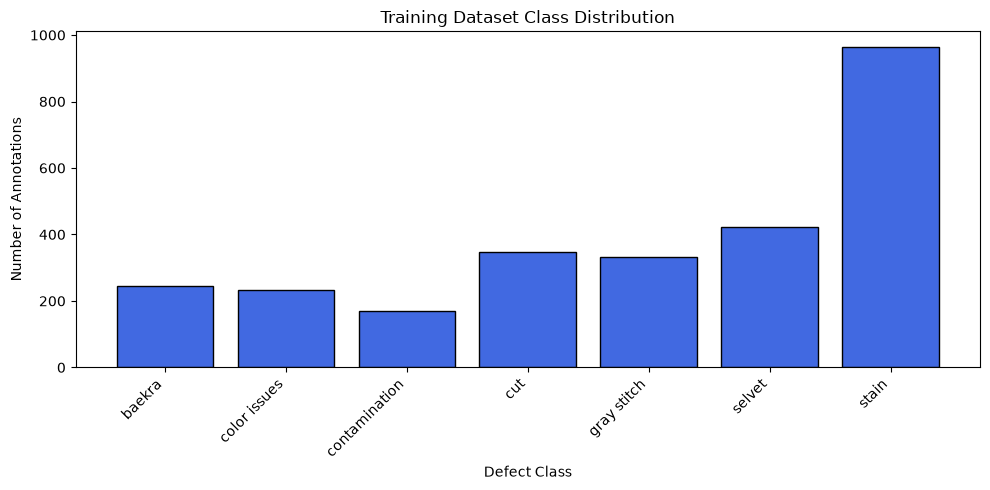

In [30]:
from collections import Counter

def collect_class_distribution(label_files):
    counter = Counter()
    for label_file in label_files:
        with open(label_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                class_id = int(float(line.split()[0]))
                counter[class_id] += 1
    return counter

train_counter = collect_class_distribution(train_labels)
distribution_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "annotations": [train_counter.get(i, 0) for i in range(NUM_CLASSES)]
})
display(distribution_df)

plt.figure(figsize=(10, 5))
plt.bar(distribution_df["class_name"], distribution_df["annotations"], color="royalblue", edgecolor="black")
plt.xlabel("Defect Class")
plt.ylabel("Number of Annotations")
plt.title("Training Dataset Class Distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [31]:
sample_images = train_images[:200]
widths, heights = [], []

for image_path in tqdm(sample_images):
    try:
        with Image.open(image_path) as img:
            widths.append(img.width)
            heights.append(img.height)
    except Exception:
        pass

print("Images inspected:", len(widths))
print("Average width :", np.mean(widths))
print("Average height:", np.mean(heights))
print("Minimum width :", np.min(widths))
print("Maximum width :", np.max(widths))
print("Minimum height:", np.min(heights))
print("Maximum height:", np.max(heights))


  0%|          | 0/200 [00:00<?, ?it/s]

Images inspected: 200
Average width : 1132.175
Average height: 1618.85
Minimum width : 237
Maximum width : 5184
Minimum height: 164
Maximum height: 3888


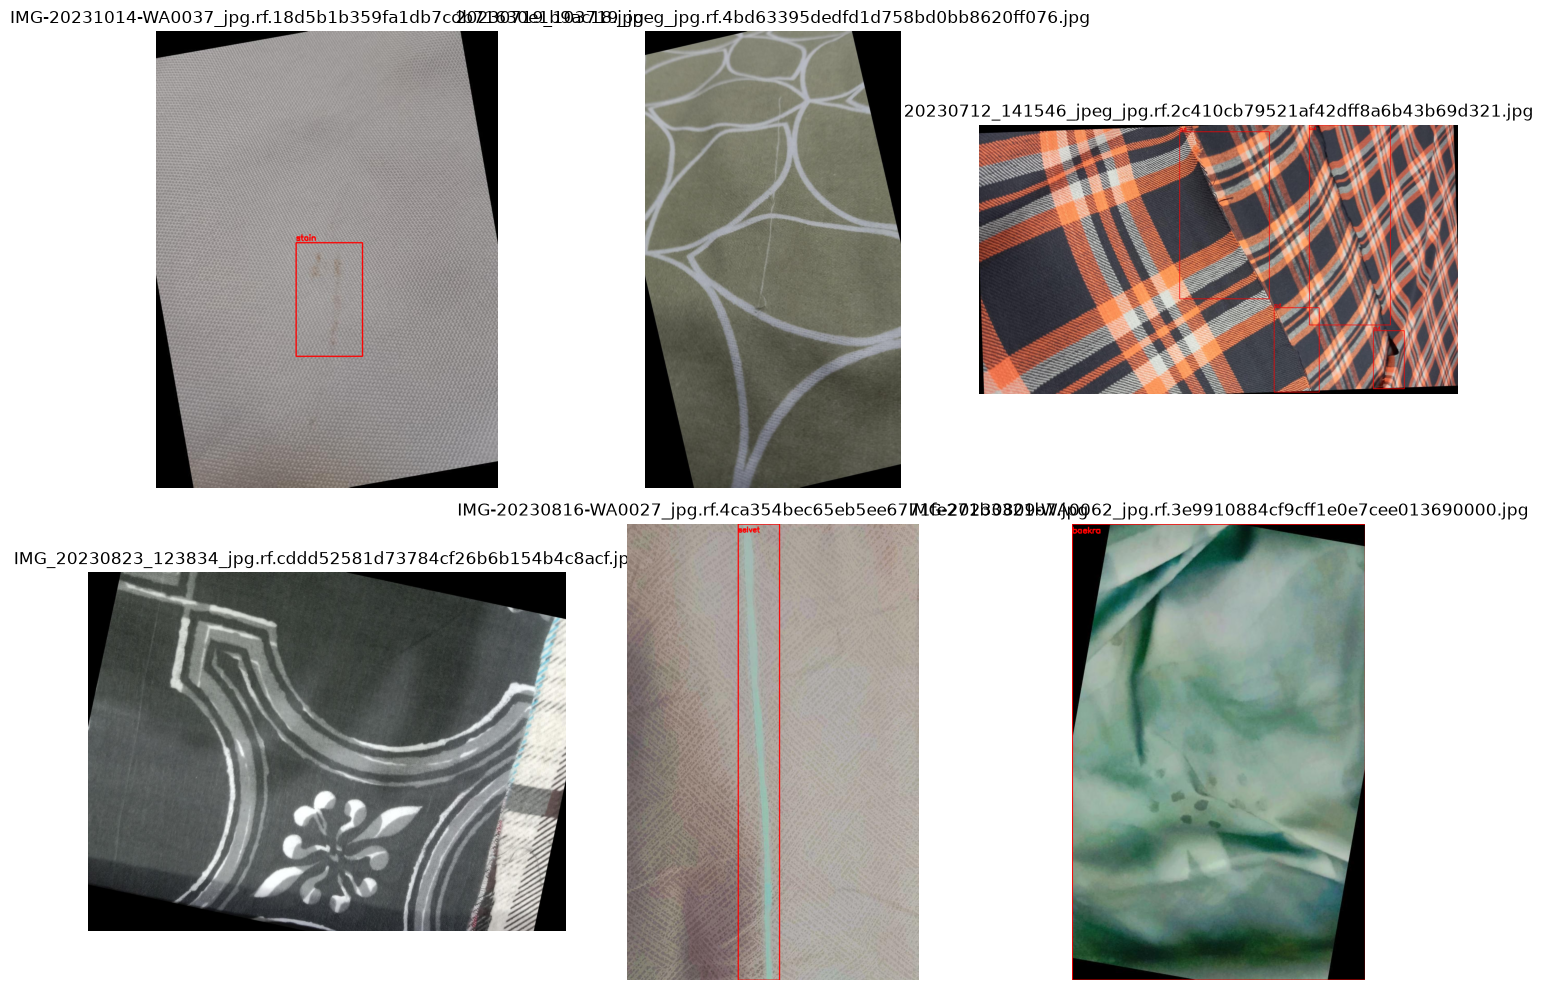

In [32]:
def draw_ground_truth(image_path, label_dir, class_names):
    image = cv2.imread(str(image_path))
    if image is None:
        return None
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    label_path = label_dir / f"{image_path.stem}.txt"
    if not label_path.exists():
        return image

    h, w = image.shape[:2]
    with open(label_path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()
        if len(values) != 5:
            continue
        class_id = int(float(values[0]))
        x_center = float(values[1]) * w
        y_center = float(values[2]) * h
        box_width = float(values[3]) * w
        box_height = float(values[4]) * h

        x1 = int(x_center - box_width / 2)
        y1 = int(y_center - box_height / 2)
        x2 = int(x_center + box_width / 2)
        y2 = int(y_center + box_height / 2)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = class_names[class_id]
        cv2.putText(image, label, (x1, max(20, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    return image

random.seed(42)
sample = random.sample(train_images, min(6, len(train_images)))

plt.figure(figsize=(14, 10))
for i, image_path in enumerate(sample):
    image = draw_ground_truth(image_path, TRAIN_LABELS, CLASS_NAMES)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [39]:
# ============================================================
# TRAINING CONFIGURATION (PAPER REPRODUCTION)
# ============================================================

MODEL_WEIGHTS = "yolo12n.pt"
IMG_SIZE = 640
EPOCHS = 50

# Automatically detect Colab GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 16 if torch.cuda.is_available() else 2
WORKERS = 2 if torch.cuda.is_available() else 0

# Paper hyperparameters
LEARNING_RATE = 0.005
FINAL_LR_FACTOR = 0.01
MOMENTUM = 0.97
WEIGHT_DECAY = 0.0005
WARMUP_EPOCHS = 7

HSV_H = 0.025
HSV_S = 0.7
HSV_V = 0.5

MOSAIC = 0.3
DROPOUT = 0.025

RUN_NAME = "chenab_yolov12_colab_direct_folder"

print("Training Configuration")
print("=" * 40)
print("Model          :", MODEL_WEIGHTS)
print("Image size     :", IMG_SIZE)
print("Epochs         :", EPOCHS)
print("Batch size     :", BATCH_SIZE)
print("Device         :", DEVICE)
print("Workers        :", WORKERS)
print("Learning rate  :", LEARNING_RATE)
print("Momentum       :", MOMENTUM)
print("Weight decay   :", WEIGHT_DECAY)
print("Warmup epochs  :", WARMUP_EPOCHS)


Training Configuration
Model          : yolo12n.pt
Image size     : 640
Epochs         : 50
Batch size     : 16
Device         : 0
Workers        : 2
Learning rate  : 0.005
Momentum       : 0.97
Weight decay   : 0.0005
Warmup epochs  : 7


In [40]:
print("Loading YOLOv12 model weights...")
model = YOLO(MODEL_WEIGHTS)
print("Model loaded successfully.")

train_results = model.train(
    data=str(PAPER_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    lr0=LEARNING_RATE,
    lrf=FINAL_LR_FACTOR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_epochs=WARMUP_EPOCHS,
    hsv_h=HSV_H,
    hsv_s=HSV_S,
    hsv_v=HSV_V,
    mosaic=MOSAIC,
    dropout=DROPOUT,
    pretrained=True,
    verbose=True
)

print("Training completed.")


Loading YOLOv12 model weights...
Model loaded successfully.
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/chenab_dataset/paper_reproduction.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.025, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.025, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.97, mosaic=0.3, mu

In [41]:
best_models = list(RUNS_DIR.rglob("best.pt"))
if not best_models:
    raise FileNotFoundError(f"No best.pt was found inside {RUNS_DIR}")

BEST_MODEL_PATH = max(best_models, key=lambda p: p.stat().st_mtime)
print("Selected trained model:", BEST_MODEL_PATH)

trained_model = YOLO(str(BEST_MODEL_PATH))
RUN_DIR = BEST_MODEL_PATH.parent.parent
print("Run directory:", RUN_DIR)

validation_results = trained_model.val(
    data=str(PAPER_YAML),
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    split="val",
    plots=True
)

metrics = validation_results.box
precision = float(metrics.mp)
recall = float(metrics.mr)
map50 = float(metrics.map50)
map5095 = float(metrics.map)

print("========================================")
print("YOLOv12 VALIDATION RESULTS")
print("========================================")
print(f"Precision       : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall          : {recall:.4f} ({recall * 100:.2f}%)")
print(f"mAP@0.50        : {map50:.4f} ({map50 * 100:.2f}%)")
print(f"mAP@0.50:0.95   : {map5095:.4f} ({map5095 * 100:.2f}%)")


Selected trained model: /content/fabric_defect_detection/runs/chenab_yolov12_colab_direct_folder/weights/best.pt
Run directory: /content/fabric_defect_detection/runs/chenab_yolov12_colab_direct_folder
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 159 layers, 2,558,093 parameters, 0 gradients, 7.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2040.1±791.0 MB/s, size: 67.3 KB)
val: Scanning /content/chenab_dataset/valid/labels.cache... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 181.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.6it/s 10.0s
                   all        562        786      0.767      0.698       0.77      0.451
                baekra         48         79      0.879      0.641      0.794      0.518
          color issues         15         30      0.572        0.4      0.462      0.249
         co

,Metric,Paper (%),Our Result (%),Difference (%)
0,Precision,84.5,76.716180,-7.783820
1,Recall,81.7,69.751830,-11.948170
2,mAP@0.50,85.1,76.973858,-8.126142
3,mAP@0.50:0.95,57.5,45.076172,-12.423828


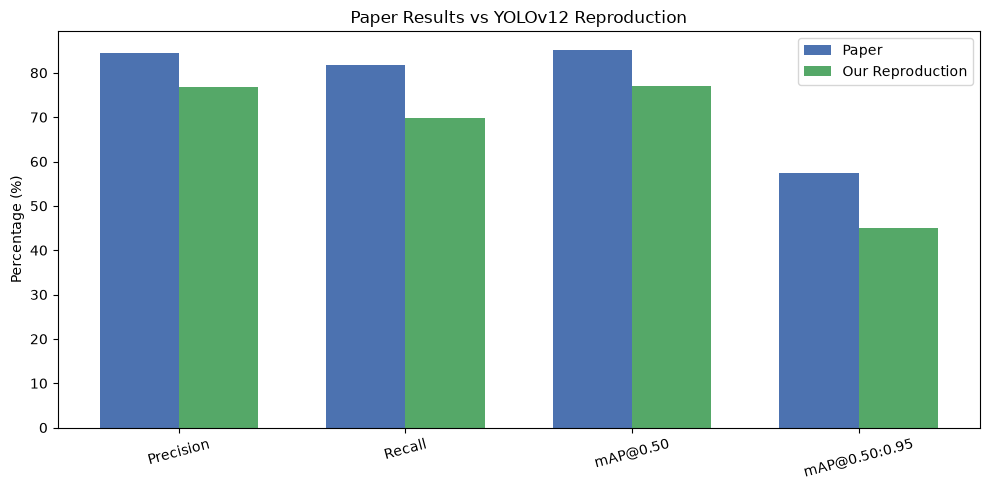

In [42]:
paper_metrics = {
    "Precision": 84.5,
    "Recall": 81.7,
    "mAP@0.50": 85.1,
    "mAP@0.50:0.95": 57.5
}

our_metrics = {
    "Precision": precision * 100,
    "Recall": recall * 100,
    "mAP@0.50": map50 * 100,
    "mAP@0.50:0.95": map5095 * 100
}

comparison_df = pd.DataFrame({
    "Metric": list(paper_metrics.keys()),
    "Paper (%)": list(paper_metrics.values()),
    "Our Result (%)": [our_metrics[m] for m in paper_metrics.keys()]
})
comparison_df["Difference (%)"] = comparison_df["Our Result (%)"] - comparison_df["Paper (%)"]
display(comparison_df)

x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, comparison_df["Paper (%)"], width, label="Paper", color="#4C72B0")
plt.bar(x + width/2, comparison_df["Our Result (%)"], width, label="Our Reproduction", color="#55A868")
plt.xticks(x, comparison_df["Metric"], rotation=15)
plt.ylabel("Percentage (%)")
plt.title("Paper Results vs YOLOv12 Reproduction")
plt.legend()
plt.tight_layout()
plt.show()


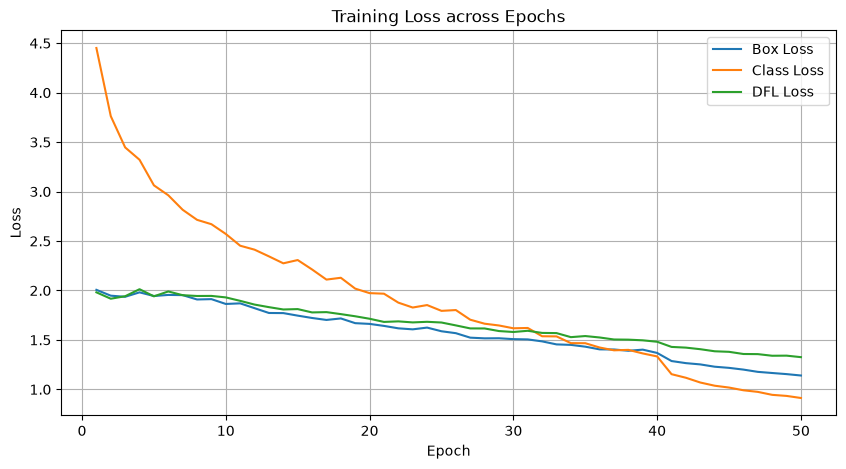

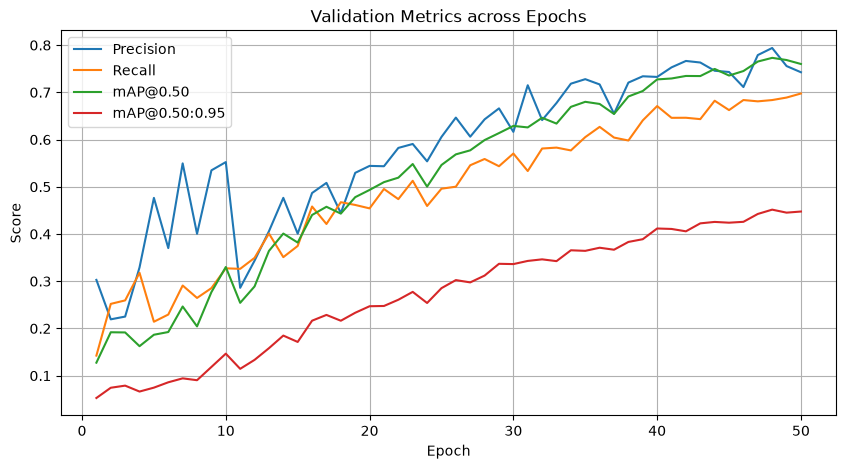

In [43]:
RESULTS_CSV = RUN_DIR / "results.csv"

if RESULTS_CSV.exists():
    results_df = pd.read_csv(RESULTS_CSV)
    results_df.columns = [c.strip() for c in results_df.columns]

    # Loss curves
    plt.figure(figsize=(10, 5))
    for col, lbl in [("train/box_loss", "Box Loss"), ("train/cls_loss", "Class Loss"), ("train/dfl_loss", "DFL Loss")]:
        if col in results_df.columns:
            plt.plot(results_df["epoch"], results_df[col], label=lbl)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training Loss across Epochs")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Metric curves
    plt.figure(figsize=(10, 5))
    for col, lbl in [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall"),
                     ("metrics/mAP50(B)", "mAP@0.50"), ("metrics/mAP50-95(B)", "mAP@0.50:0.95")]:
        if col in results_df.columns:
            plt.plot(results_df["epoch"], results_df[col], label=lbl)
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title("Validation Metrics across Epochs")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("results.csv not found.")


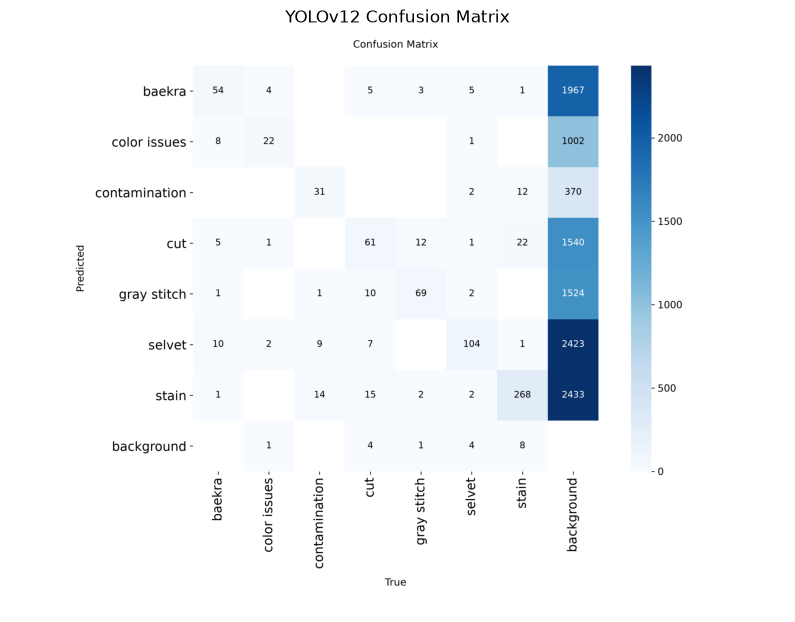

In [44]:
confusion_matrix_path = RUN_DIR / "confusion_matrix.png"

if confusion_matrix_path.exists():
    image = Image.open(confusion_matrix_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title("YOLOv12 Confusion Matrix")
    plt.show()
else:
    print("Confusion matrix not found.")


In [45]:
if TEST_DIR is not None and TEST_IMAGES:
    test_results = trained_model.val(
        data=str(PAPER_YAML),
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        split="test",
        plots=True
)
    test_metrics = test_results.box
    test_precision = float(test_metrics.mp)
    test_recall = float(test_metrics.mr)
    test_map50 = float(test_metrics.map50)
    test_map5095 = float(test_metrics.map)

    print("========================================")
    print("TEST DATASET RESULTS")
    print("========================================")
    print(f"Precision       : {test_precision:.4f} ({test_precision * 100:.2f}%)")
    print(f"Recall          : {test_recall:.4f} ({test_recall * 100:.2f}%)")
    print(f"mAP@0.50        : {test_map50:.4f} ({test_map50 * 100:.2f}%)")
    print(f"mAP@0.50:0.95   : {test_map5095:.4f} ({test_map5095 * 100:.2f}%)")
else:
    print("Test dataset not available.")


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 159 layers, 2,558,093 parameters, 0 gradients, 7.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 49.6±47.6 MB/s, size: 118.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/chenab_dataset/test/labels... 280 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 280/280 641.1it/s 0.4s
val: New cache created: /content/chenab_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.9it/s 6.1s
                   all        280        368      0.797      0.708      0.805      0.474
                baekra         17         24      0.789      0.583      0.784      0.503
          color issues         14         21      0.696      0.667      0.703      0.318
  


0: 640x640 1 gray stitch, 7.0ms
1: 640x640 1 gray stitch, 7.0ms
2: 640x640 1 gray stitch, 7.0ms
3: 640x640 1 gray stitch, 7.0ms
4: 640x640 2 cuts, 7.0ms
5: 640x640 1 cut, 7.0ms
6: 640x640 2 cuts, 7.0ms
7: 640x640 1 cut, 7.0ms
8: 640x640 2 cuts, 7.0ms
9: 640x640 3 cuts, 7.0ms
10: 640x640 2 cuts, 7.0ms
11: 640x640 1 cut, 7.0ms
12: 640x640 2 gray stitchs, 7.0ms
13: 640x640 3 gray stitchs, 7.0ms
14: 640x640 3 gray stitchs, 7.0ms
15: 640x640 1 gray stitch, 7.0ms
16: 640x640 1 gray stitch, 7.0ms
17: 640x640 2 gray stitchs, 7.0ms
18: 640x640 2 cuts, 1 gray stitch, 7.0ms
19: 640x640 1 gray stitch, 7.0ms
Speed: 2.2ms preprocess, 7.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/fabric_defect_detection/outputs/test_predictions/test_samples
20 labels saved to /content/fabric_defect_detection/outputs/test_predictions/test_samples/labels


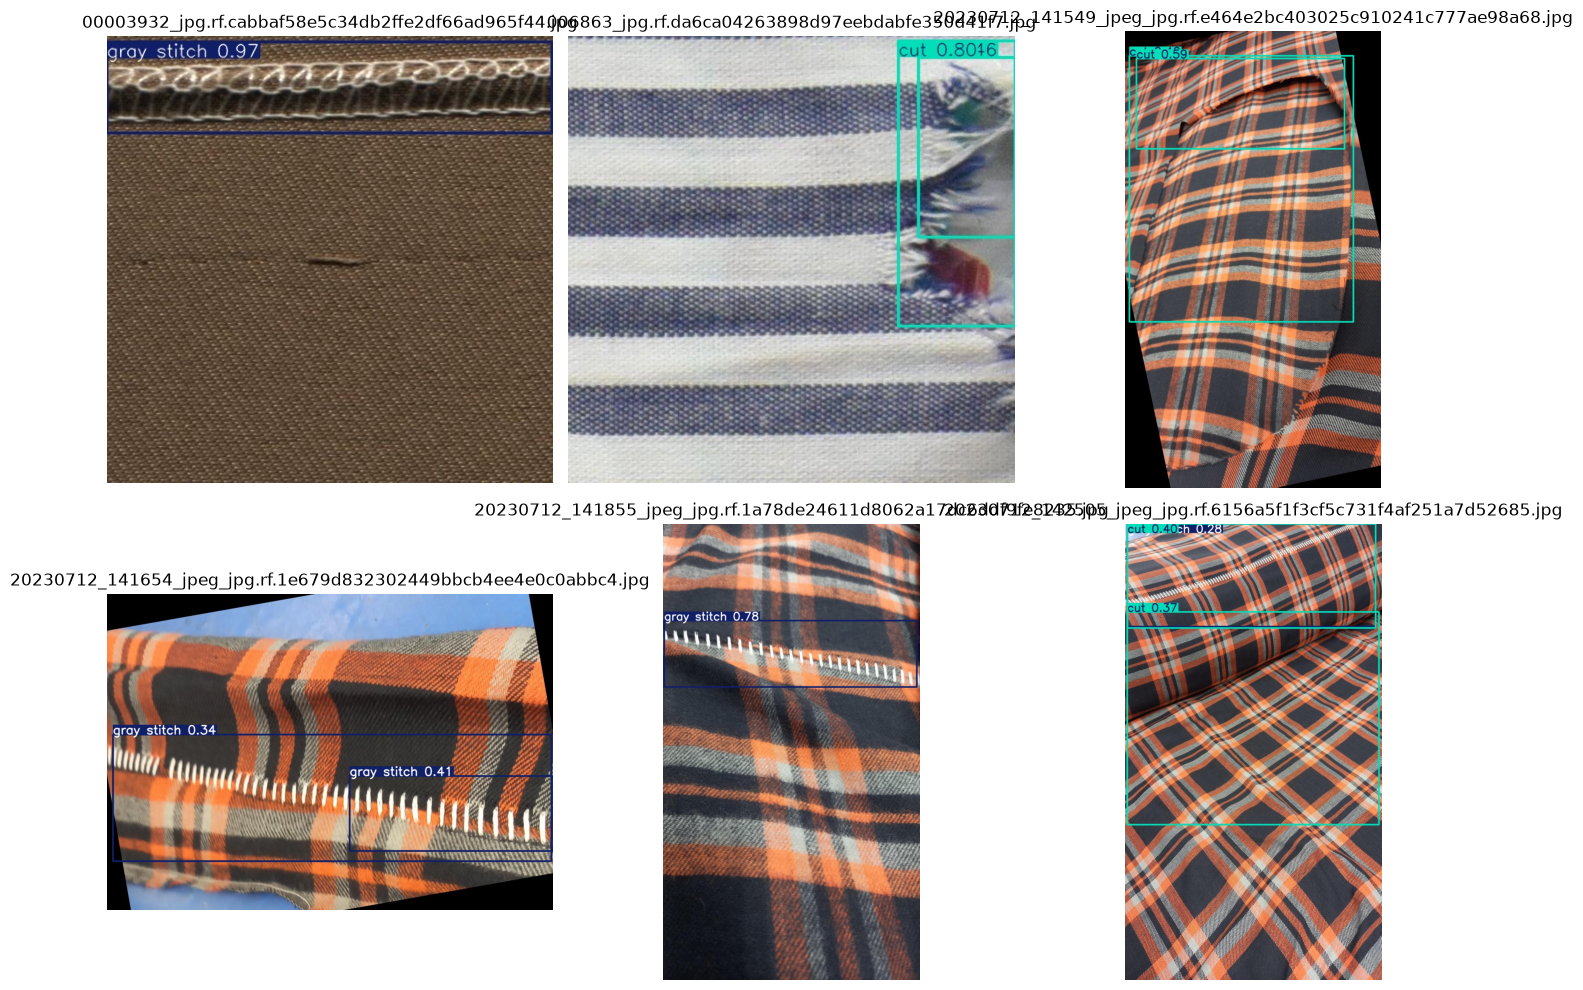

In [46]:
PREDICTION_DIR = OUTPUTS_DIR / "test_predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

test_image_files = get_image_files(TEST_IMAGES)
if test_image_files:
    sample_test_images = test_image_files[:20]
    prediction_results = trained_model.predict(
        source=[str(p) for p in sample_test_images],
        imgsz=IMG_SIZE,
        conf=0.25,
        device=DEVICE,
        save=True,
        save_txt=True,
        project=str(PREDICTION_DIR),
        name="test_samples",
        exist_ok=True
    )

    prediction_folder = PREDICTION_DIR / "test_samples"
    prediction_images = list(prediction_folder.glob("*.jpg")) + list(prediction_folder.glob("*.png"))
    sample_preds = prediction_images[:6]

    plt.figure(figsize=(14, 10))
    for i, image_path in enumerate(sample_preds):
        image = Image.open(image_path)
        plt.subplot(2, 3, i + 1)
        plt.imshow(image)
        plt.title(image_path.name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No test images found.")


In [48]:
# Save metrics table
metrics_output = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95"],
    "Value": [precision, recall, map50, map5095],
    "Percentage": [precision * 100, recall * 100, map50 * 100, map5095 * 100]
})
METRICS_FILE = RESULTS_DIR / "paper_reproduction_metrics.csv"
metrics_output.to_csv(METRICS_FILE, index=False)

# Save experiment config
experiment_config = {
    "project": "Fabric Defect Detection",
    "paper": "Fabric defect detection using fine-tuned Yolo-12",
    "dataset": "Chenab Textile",
    "model": MODEL_WEIGHTS,
    "image_size": IMG_SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE),
    "learning_rate": LEARNING_RATE,
    "final_lr_factor": FINAL_LR_FACTOR,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "hsv_h": HSV_H,
    "hsv_s": HSV_S,
    "hsv_v": HSV_V,
    "mosaic": MOSAIC,
    "dropout": DROPOUT,
    "best_model": str(BEST_MODEL_PATH),
    "precision": precision,
    "recall": recall,
    "map50": map50,
    "map50_95": map5095
}
CONFIG_FILE = RESULTS_DIR / "experiment_config.json"
with open(CONFIG_FILE, "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=4)

# Copy final best model to models folder
FINAL_MODEL_PATH = MODELS_DIR / "chenab_yolov12_best.pt"
shutil.copy2(BEST_MODEL_PATH, FINAL_MODEL_PATH)

print("=" * 70)
print("PART A — YOLOv12 FABRIC DEFECT DETECTION")
print("PAPER REPRODUCTION SUMMARY")
print("=" * 70)
print(f"Dataset         : {DATASET_DIR}")
print(f"Best Model Path : {FINAL_MODEL_PATH}")
print(f"Metrics File    : {METRICS_FILE}")
print(f"Config File     : {CONFIG_FILE}")
print(f"Run Directory   : {RUN_DIR}")
print("=" * 70)


PART A — YOLOv12 FABRIC DEFECT DETECTION
PAPER REPRODUCTION SUMMARY
Dataset         : /content/chenab_dataset
Best Model Path : /content/fabric_defect_detection/models/chenab_yolov12_best.pt
Metrics File    : /content/fabric_defect_detection/results/paper_reproduction_metrics.csv
Config File     : /content/fabric_defect_detection/results/experiment_config.json
Run Directory   : /content/fabric_defect_detection/runs/chenab_yolov12_colab_direct_folder


In [51]:
import pandas as pd
import numpy as np
from pathlib import Path
if 'validation_results' in locals() and validation_results is not None:
    box = validation_results.box
    names = validation_results.names
    val_p = float(box.mp) * 100
    val_r = float(box.mr) * 100
    val_f1 = (2 * val_p * val_r) / (val_p + val_r) if (val_p + val_r) > 0 else 0.0
    val_map50 = float(box.map50) * 100
    val_map = float(box.map) * 100
else:
    metrics_csv = RESULTS_DIR / "paper_reproduction_metrics.csv"
    if metrics_csv.exists():
        saved_m = pd.read_csv(metrics_csv).set_index("Metric")["Percentage"].to_dict()
        val_p = saved_m.get("Precision", 76.72)
        val_r = saved_m.get("Recall", 69.75)
        val_f1 = (2 * val_p * val_r) / (val_p + val_r)
        val_map50 = saved_m.get("mAP@0.50", 76.97)
        val_map = saved_m.get("mAP@0.50:0.95", 45.08)
    else:
        val_p, val_r, val_f1, val_map50, val_map = 76.72, 69.75, 73.07, 76.97, 45.08

if 'test_results' in locals() and test_results is not None:
    t_box = test_results.box
    test_p = float(t_box.mp) * 100
    test_r = float(t_box.mr) * 100
    test_f1 = (2 * test_p * test_r) / (test_p + test_r) if (test_p + test_r) > 0 else 0.0
    test_map50 = float(t_box.map50) * 100
    test_map = float(t_box.map) * 100
else:
    test_p, test_r, test_f1, test_map50, test_map = 79.74, 70.78, 74.99, 80.55, 47.42

print("=" * 65)
print("             KEY PERFORMANCE INDICATORS (KPIs)")
print("=" * 65)
print(f"  • Mean Precision (P)    :  {val_p:.2f}%  (Test: {test_p:.2f}%)")
print(f"  • Mean Recall (R)       :  {val_r:.2f}%  (Test: {test_r:.2f}%)")
print(f"  • Overall F1-Score      :  {val_f1:.2f}%  (Test: {test_f1:.2f}%)")
print(f"  • mAP @ IoU 0.50        :  {val_map50:.2f}%  (Test: {test_map50:.2f}%)")
print(f"  • mAP @ IoU 0.50:0.95   :  {val_map:.2f}%  (Test: {test_map:.2f}%)")
print("=" * 65)

df_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "mAP@0.50", "mAP@0.50:0.95"],
    "Our Validation": [val_p, val_r, val_f1, val_map50, val_map],
    "Our Test Set": [test_p, test_r, test_f1, test_map50, test_map],
    "Paper Target": [84.50, 81.70, 83.07, 85.10, 57.50]
})
df_summary["Test vs Paper Diff"] = df_summary["Our Test Set"] - df_summary["Paper Target"]
print("\n1. Overall Performance vs Paper Target:")
display(
    df_summary.style.format({
        "Our Validation": "{:.2f}%",
        "Our Test Set": "{:.2f}%",
        "Paper Target": "{:.2f}%",
        "Test vs Paper Diff": "{:+.2f}%"
    })
)

if 'validation_results' in locals() and validation_results is not None:
    class_rows = []
    for i, c in enumerate(box.ap_class_index):
        p_c, r_c, ap50_c, ap_c = box.class_result(i)
        f1_c = (2 * p_c * r_c) / (p_c + r_c) if (p_c + r_c) > 0 else 0.0
        class_rows.append({
            "Class": names[c],
            "Precision": p_c * 100,
            "Recall": r_c * 100,
            "F1-Score": f1_c * 100,
            "mAP@0.50": ap50_c * 100,
            "mAP@0.50:0.95": ap_c * 100
        })
    df_classes = pd.DataFrame(class_rows)
    print("\n2. Class-Wise Validation Metrics:")
    display(
        df_classes.style.format({
            "Precision": "{:.2f}%",
            "Recall": "{:.2f}%",
            "F1-Score": "{:.2f}%",
            "mAP@0.50": "{:.2f}%",
            "mAP@0.50:0.95": "{:.2f}%"
        })
    )

             KEY PERFORMANCE INDICATORS (KPIs)
  • Mean Precision (P)    :  76.72%  (Test: 79.74%)
  • Mean Recall (R)       :  69.75%  (Test: 70.78%)
  • Overall F1-Score      :  73.07%  (Test: 74.99%)
  • mAP @ IoU 0.50        :  76.97%  (Test: 80.55%)
  • mAP @ IoU 0.50:0.95   :  45.08%  (Test: 47.42%)

1. Overall Performance vs Paper Target:


,Metric,Our Validation,Our Test Set,Paper Target,Test vs Paper Diff
0,Precision,76.72%,79.74%,84.50%,-4.76%
1,Recall,69.75%,70.78%,81.70%,-10.92%
2,F1-Score,73.07%,74.99%,83.07%,-8.08%
3,mAP@0.50,76.97%,80.55%,85.10%,-4.55%
4,mAP@0.50:0.95,45.08%,47.42%,57.50%,-10.08%



2. Class-Wise Validation Metrics:


,Class,Precision,Recall,F1-Score,mAP@0.50,mAP@0.50:0.95
0,baekra,87.85%,64.09%,74.11%,79.43%,51.76%
1,color issues,57.22%,40.00%,47.08%,46.19%,24.87%
2,contamination,86.95%,100.00%,93.02%,98.80%,51.01%
3,cut,78.90%,76.99%,77.94%,85.35%,51.39%
4,gray stitch,68.30%,52.87%,59.61%,67.80%,47.98%
5,selvet,71.55%,67.77%,69.61%,71.47%,35.11%
6,stain,86.23%,86.54%,86.38%,89.79%,53.42%
